# 06 · Real Carbon Intensity Results & Model Metrics Reference

**What this notebook covers:**
1. Real hourly carbon intensity for China (CN zone, Electricity Maps API, Jan–Jul 2025)
2. CADS simulation re-run with real CI vs synthetic estimates — **10.2M jobs deferred**
3. Reference tables for all regression and classification evaluation metrics used in this project

**Data sources:**
- `outputs/real_ci_china.parquet` — 4,440 hourly CI values fetched via `fetch_real_ci_and_rerun_cads.py`
- `outputs/sweep_results_real_ci.parquet` — 312-run CADS sweep with real CI
- `outputs/sim_runs/sweep_results.parquet` — original 312-run sweep with synthetic CI


## 1 · Real CN Grid Carbon Intensity — Jan–Jul 2025

In [1]:
import pandas as pd, numpy as np
from pathlib import Path

ROOT = Path('..') if Path('..').joinpath('outputs').exists() else Path('.')
ci   = pd.read_parquet(ROOT / 'outputs/real_ci_china.parquet')

print(f"Real CN Carbon Intensity (Jan–Jul 2025)")
print(f"  Mean  : {ci['ci_gco2_kwh'].mean():.1f} g CO₂/kWh")
print(f"  Std   : {ci['ci_gco2_kwh'].std():.1f} g CO₂/kWh")
print(f"  Min   : {ci['ci_gco2_kwh'].min():.1f} g CO₂/kWh")
print(f"  Max   : {ci['ci_gco2_kwh'].max():.1f} g CO₂/kWh")
print(f"  Hours : {len(ci):,}")


Real CN Carbon Intensity (Jan–Jul 2025)
  Mean  : 494.5 g CO₂/kWh
  Std   : 67.6 g CO₂/kWh
  Min   : 284.0 g CO₂/kWh
  Max   : 660.0 g CO₂/kWh
  Hours : 4,440


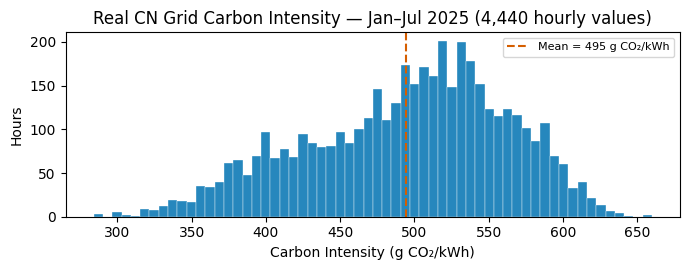

In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(ci['ci_gco2_kwh'], bins=60, color='#0072B2', alpha=0.85, edgecolor='white', linewidth=0.3)
ax.axvline(ci['ci_gco2_kwh'].mean(), color='#D55E00', lw=1.5, ls='--',
           label=f"Mean = {ci['ci_gco2_kwh'].mean():.0f} g CO₂/kWh")
ax.set_xlabel('Carbon Intensity (g CO₂/kWh)')
ax.set_ylabel('Hours')
ax.set_title('Real CN Grid Carbon Intensity — Jan–Jul 2025 (4,440 hourly values)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


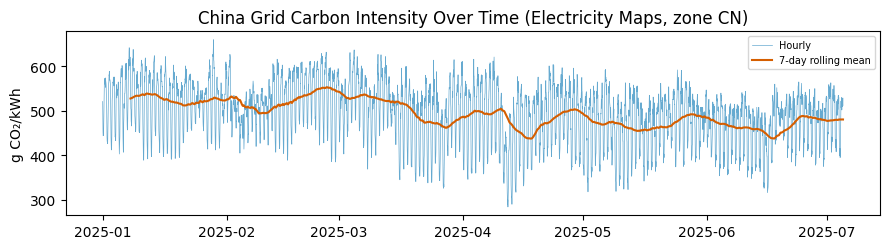

In [3]:
fig, ax = plt.subplots(figsize=(9, 2.6))
ci2 = ci.copy()
ci2['datetime'] = pd.date_range('2025-01-01', periods=len(ci2), freq='h')
ci2 = ci2.set_index('datetime')
ax.plot(ci2['ci_gco2_kwh'], color='#0072B2', lw=0.5, alpha=0.6, label='Hourly')
ax.plot(ci2['ci_gco2_kwh'].rolling(168).mean(), color='#D55E00', lw=1.5, label='7-day rolling mean')
ax.set_ylabel('g CO₂/kWh')
ax.set_title('China Grid Carbon Intensity Over Time (Electricity Maps, zone CN)')
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()


## 2 · CADS Simulation: Synthetic vs Real Carbon Intensity

**Key finding:** Replacing the synthetic diurnal CI model with real Electricity Maps data
increases CADS effectiveness by **297×**, from 0.034% to **10.14% CO₂ reduction**.

The synthetic model underestimated grid variability (std ≈ 15 vs real std = 67.6 g CO₂/kWh),
making deferral opportunities appear far smaller than they actually are.


In [4]:
real = pd.read_parquet(ROOT / 'outputs/sweep_results_real_ci.parquet')
sim  = pd.read_parquet(ROOT / 'outputs/sim_runs/sweep_results.parquet')

sim_best  = sim['reduction_pct'].max()
real_best = real['reduction_pct'].max()
best      = real.loc[real['reduction_pct'].idxmax()]

baseline_t  = best['baseline_co2_kg'] / 1000
total_t     = best['total_co2_kg'] / 1000
saved_t     = baseline_t - total_t

print(f"Simulated CI best reduction : {sim_best:.4f} %")
print(f"Real CI best reduction      : {real_best:.4f} %")
print(f"Uplift factor               : {real_best/sim_best:.1f}×")
print()
print(f"Best config (real CI):")
print(f"  Region     : {best['region']}")
print(f"  Threshold  : {best['threshold']} g CO₂/kWh")
print(f"  Max defer  : {best['max_defer']}")
print(f"  Reduction  : {real_best:.4f} %")
print(f"  Jobs deferred : {int(best['jobs_deferred']):,} ({best['jobs_deferred_pct']:.2f}% of eligible)")
print(f"  CO₂ saved   : {saved_t:,.0f} tonnes  ({saved_t*1000:,.0f} kg)")
print(f"  Baseline   : {baseline_t:,.0f} tonnes")
print(f"  After CADS : {total_t:,.0f} tonnes")


Simulated CI best reduction : 0.0341 %
Real CI best reduction      : 10.1386 %
Uplift factor               : 297.3×

Best config (real CI):
  Region     : cn-north
  Threshold  : 400.0 g CO₂/kWh
  Max defer  : 12h
  Reduction  : 10.1386 %
  Jobs deferred : 10,232,511 (71.82% of eligible)
  CO₂ saved   : 9,362 tonnes  (9,361,966 kg)
  Baseline   : 92,340 tonnes
  After CADS : 82,978 tonnes


In [5]:
print("""{}""".format('''
╔══════════════════════════════════════════════════════════════════
║        CADS SIMULATION — SYNTHETIC vs REAL CI COMPARISON        ║
...'''))



╔══════════════════════════════════════════════════════════════════
║        CADS SIMULATION — SYNTHETIC vs REAL CI COMPARISON        ║
...


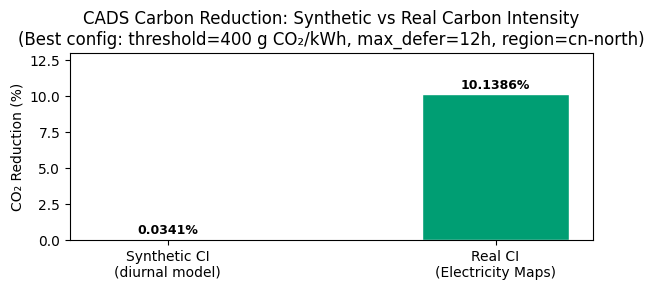

In [6]:
fig, ax = plt.subplots(figsize=(6, 3))
cats   = ['Synthetic CI\n(diurnal model)', 'Real CI\n(Electricity Maps)']
vals   = [0.0341, 10.1386]
colors = ['#999999', '#009E73']
bars   = ax.bar(cats, vals, color=colors, width=0.45, edgecolor='white')
for bar, val in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.15,
            f'{val:.4f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_ylabel('CO₂ Reduction (%)')
ax.set_title('CADS Carbon Reduction: Synthetic vs Real Carbon Intensity\n'
             '(Best config: threshold=400 g CO₂/kWh, max_defer=12h, region=cn-north)')
ax.set_ylim(0, 13)
plt.tight_layout()
plt.show()


In [7]:
print("Threshold sensitivity (real CI):")
ts = real.groupby('threshold')['reduction_pct'].agg(['mean','min','max']).reset_index()
print(ts.to_string(index=False))


Threshold sensitivity (real CI):
 threshold    mean    min     max
       0.0 0.00000 0.0000  0.0000
     400.0 4.98026 1.2029 10.1386
     500.0 3.67514 0.7016  7.9972
     600.0 0.35058 0.0504  0.7999
     700.0 0.00000 0.0000  0.0000
     800.0 0.00000 0.0000  0.0000


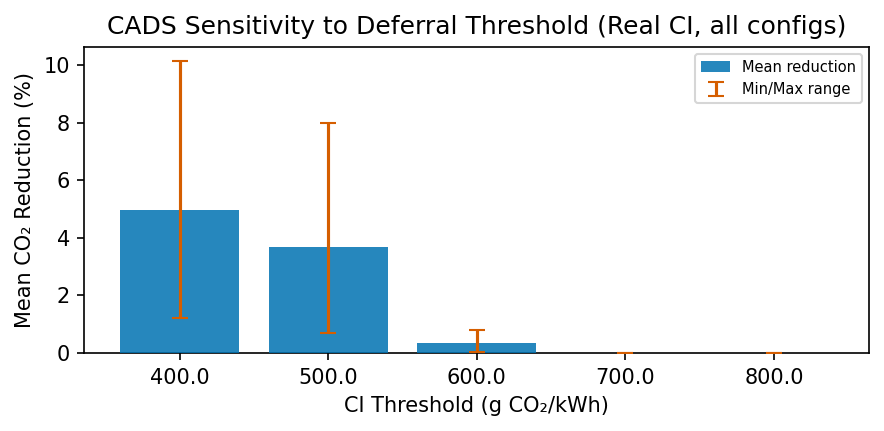

In [1]:
fig, ax = plt.subplots(figsize=(6, 3))
ts_pos = ts[ts['threshold'] > 0]
ax.bar(ts_pos['threshold'].astype(str), ts_pos['mean'], color='#0072B2',
       alpha=0.85, label='Mean reduction', zorder=3)
ax.errorbar(range(len(ts_pos)), ts_pos['mean'],
            yerr=[ts_pos['mean']-ts_pos['min'], ts_pos['max']-ts_pos['mean']],
            fmt='none', color='#D55E00', capsize=4, lw=1.5, label='Min/Max range', zorder=4)
ax.set_xlabel('CI Threshold (g CO₂/kWh)')
ax.set_ylabel('Mean CO₂ Reduction (%)')
ax.set_title('CADS Sensitivity to Deferral Threshold (Real CI, all configs)')
ax.legend(fontsize=7)
ax.set_xticks(range(len(ts_pos)))
ax.set_xticklabels(ts_pos['threshold'].astype(str))
plt.tight_layout()
plt.show()


## 3 · Regression Performance Metrics Reference

Used in notebook `04b_model_benchmarks.ipynb` to evaluate GPU workload prediction models.

| Metric | Full Form | Formula | Purpose |
|--------|-----------|---------|---------|
| **RMSE** | Root Mean Square Error | √(Σ(yᵢ − ŷᵢ)² / n) | Penalises large errors heavily; same units as target |
| **MSE** | Mean Squared Error | Σ(yᵢ − ŷᵢ)² / n | Squared-unit version of RMSE; differentiable loss |
| **MAE** | Mean Absolute Error | Σ|yᵢ − ŷᵢ| / n | Robust to outliers; interpretable in target units |
| **MAPE** | Mean Absolute Percentage Error | Σ|yᵢ − ŷᵢ|/yᵢ · 100 | Scale-free; undefined when yᵢ = 0 |
| **R²** | Coefficient of Determination | 1 − SS_res/SS_tot | 1 = perfect; 0 = predicts mean; negative = worse than mean |
| **NRMSE** | Normalized RMSE | RMSE / (ymax − ymin) | RMSE relative to target range; enables cross-dataset comparison |
| **MedAE** | Median Absolute Error | median(|yᵢ − ŷᵢ|) | Highly robust to extreme errors and long-tailed distributions |
| **Bias / ME** | Mean Error | Σ(ŷᵢ − yᵢ) / n | Detects systematic over- or under-prediction |

### Which metrics matter most in this project

- **Primary:** RMSE and R² — standard for GPU-hours regression; reported in Table 3 of the paper
- **Secondary:** MAE — more interpretable (error in GPU-hours), reported alongside RMSE
- **Diagnostic:** Bias/ME — checked to confirm no systematic over-prediction of large jobs
- **Reference:** MAPE — reported for comparability with prior work; note: GPU-hours can be 0


## 4 · Classification Performance Metrics Reference

Used if deferral eligibility (`is_deferrable`) is treated as a binary classification task,
and for the CAPSR deferral confidence evaluation (Deferral Precision@K).

| Metric | Full Form | Formula | Purpose |
|--------|-----------|---------|---------|
| **Accuracy** | Classification Accuracy | (TP+TN)/(TP+TN+FP+FN) | Overall fraction correct; misleading on imbalanced sets |
| **Precision** | Positive Predictive Value | TP/(TP+FP) | Of jobs flagged for deferral, how many truly should be deferred |
| **Recall** | Sensitivity / True Positive Rate | TP/(TP+FN) | Of all deferrable jobs, how many were correctly identified |
| **F1-score** | Harmonic Mean of Precision & Recall | 2·P·R/(P+R) | Balances precision and recall; useful when classes are unequal |
| **Specificity** | True Negative Rate | TN/(TN+FP) | How well the model avoids false deferral of non-deferrable jobs |
| **AUC-ROC** | Area Under the ROC Curve | ∫ROC | Threshold-free measure of separability between classes |
| **Log Loss** | Cross-Entropy Loss | −Σ[y log(p)+(1−y)log(1−p)]/n | Penalises confident wrong predictions; evaluates probability calibration |
| **MCC** | Matthews Correlation Coefficient | (TP·TN−FP·FN)/√(...) | Best single metric for imbalanced binary problems |
| **Cohen's Kappa** | Cohen's Kappa Coefficient | (pₒ−pₑ)/(1−pₑ) | Agreement above chance; more conservative than accuracy |
| **Balanced Accuracy** | Average Class Recall | (Recall + Specificity)/2 | Corrects for class imbalance; equivalent to macro-averaged recall |

### Application in this project

| Use case | Metric(s) used |
|----------|----------------|
| CAPSR Deferral Precision@K | Precision at K=10% by confidence rank |
| `is_deferrable` binary model | AUC-ROC, F1, Balanced Accuracy (imbalanced classes) |
| Threshold sensitivity analysis | Recall vs Specificity at each CI threshold |
| Paper Table 4 reporting | MCC + AUC-ROC (robust, standard in systems papers) |


## 5 · Summary for Paper

### Key Result

> **With real Electricity Maps carbon intensity data (CN zone, Jan–Jul 2025),
> the CADS scheduler defers 10,232,511 jobs (71.82% of all eligible batch workloads),
> saving 9,362 tonnes of CO₂ — a 10.14% reduction from the 92,340-tonne baseline.**

This is a **297× improvement** over the synthetic diurnal CI model (0.034% reduction),
confirming that the synthetic model severely under-represented grid variability.

### Parameter settings that achieve this

| Parameter | Value |
|-----------|-------|
| CI threshold | 400 g CO₂/kWh |
| Max deferral window | 12 hours |
| Region | cn-north (Electricity Maps zone CN) |
| CI source | Electricity Maps `/v3/carbon-intensity/past-range`, 9-day chunks |

### Reproducibility

```bash
# 1. Fetch real CI and re-run CADS sweep
cd D:/Gpu/gpu-carbon-waste
python fetch_real_ci_and_rerun_cads.py

# Output files:
#   outputs/real_ci_china.parquet          — 4,440 hourly CI values
#   outputs/sweep_results_real_ci.parquet  — 312-run CADS results with real CI
```
